# Cuando el camino más corto no es el mejor
### Rescate en una zona inundada: BFS vs. Búsqueda de Costo Uniforme (UCS) vs. A\*

**Integrantes:** -Castillo Gamboa Emir Ariel
                 -Dominguez Caamal Andres Said
                 -Kumul Ek Angela Rubi
                 -Pirin Solis David Antonio

  **Materia:** Fundamentos de Inteligencia Artificial  **Fecha de entrega:** 17/oct/2026

Un agente debe ir desde un punto inicial hasta un refugio en una cuadrícula con **obstáculos**, **agua profunda que impide el paso** y **zonas de inundación con distinto riesgo**. La pregunta central es:

> ¿Encontrar *una* ruta válida es lo mismo que encontrar la ruta *conveniente*?

**Cómo leer este notebook:** las secciones están numeradas; todos los números de tablas y conclusiones salen de ejecuciones reales (semillas fijas), no están escritos a mano. Si se vuelve a ejecutar con *Kernel → Restart & Run All*, se obtienen los mismos resultados.

| # | Sección |
|---|---------|
| 1 | Análisis de la "prueba trampa": errores y contradicciones detectados |
| 2 | Preparación y representación del terreno |
| 3 | Costos de desplazamiento y su justificación |
| 4 | Algoritmos: BFS, UCS, A\* (y heurística admisible) |
| 5 | Validación automática de rutas y verificador independiente |
| 6 | Visualización |
| 7 | Escenario base |
| 8 | Las cinco pruebas obligatorias |
| 9 | Prueba adicional: detección de errores de implementación (mutantes) |
| 10 | Verificación final: optimalidad, admisibilidad y pruebas aleatorias |
| 11 | Tabla resumen de pruebas |
| 12 | Decisiones de diseño, errores corregidos, conclusiones y limitaciones |
| 13 | Instrucciones de ejecución, estructura del repositorio y commits de Git |
| 14 | Declaración de uso de herramientas de IA y verificación |

## 1. Análisis de la "prueba trampa": errores y contradicciones detectados

El enunciado no trae código inicial, así que las "trampas" están en las **afirmaciones, definiciones y errores típicos de implementación** que un proyecto así invita a cometer. Se listan aquí, con su corrección, y más adelante cada una se **comprueba con una prueba real** (no se asume).

| # | Posible error / contradicción | Por qué es incorrecto | Corrección en este proyecto | Dónde se comprueba |
|---|---|---|---|---|
| E1 | Tratar "ruta más corta" como "mejor ruta". | BFS minimiza el **número de movimientos**, no el **costo por riesgo**. Con terreno no uniforme pueden diferir mucho. | Se separan las dos métricas (movimientos vs. costo) y se compara BFS contra UCS/A\*. | Prueba 5 |
| E2 | Exigir que **BFS** devuelva la ruta de **costo mínimo**. | BFS solo es óptimo en costo si todos los pasos cuestan lo mismo. Aquí no es así. | Se exige costo mínimo solo a UCS y A\*; a BFS se le exige validez y mínimo de movimientos. | Secciones 9 y 10 |
| E3 | Modelar la inundación profunda como **costo muy alto** (p. ej. 1000) en vez de **bloqueo**. | Con costo finito el agente *puede* cruzar si no hay otra salida, y el enunciado dice que algunas zonas **impiden el paso**. Además haría que un refugio aislado parezca alcanzable. | Nivel 4 = celda **no transitable** (no existe como vecino). | Pruebas 2, 3 y mutante M5 |
| E4 | Usar la **distancia de Manhattan sin escalar** como heurística. | Solo es admisible si cada paso cuesta **≥ 1** y los movimientos son de 4 direcciones. Si algún costo fuera < 1, o hubiera diagonales, sobreestima y A\* deja de ser óptimo. | `h(n) = costo_min × Manhattan(n, refugio)`; se **verifica** admisibilidad y consistencia contra costos exactos. | Sección 10, mutante M3 |
| E5 | Declarar "A\* usa una heurística admisible" **sin comprobarlo**. | Es una afirmación, no una prueba. | Se calcula el costo real restante `h*(n)` de cada celda y se comprueba `h(n) ≤ h*(n)` y consistencia. | Sección 10 |
| E6 | Confundir **ruta válida** con **ruta conveniente**. | Una ruta puede cumplir todas las restricciones y aun así ser mucho peor. | `validar_ruta` (restricciones) y `auditar` (restricciones + optimalidad) son funciones distintas. | Secciones 5, 8, 9 |
| E7 | Refugio inaccesible → devolver ruta vacía, parcial o con costo 0. | "Sin ruta" no es una ruta de longitud 0. Una ruta parcial no llega al refugio. | El resultado lleva `encontrada=False`, `ruta=None`, `costo=None`. | Prueba 3 |
| E8 | Contar el costo de la celda **inicial**, o confundir costo de **entrar** vs. **salir** de una celda. | Cambia el costo total y puede romper la admisibilidad. | Convención única: el costo de un paso es el de **entrar** a la celda destino; el inicio no cuesta. | Sección 3 |
| E9 | Que el **verificador** reutilice el mismo código/costos que el algoritmo. | Un error compartido pasaría desapercibido ("se valida a sí mismo"). | Se escribió un verificador **independiente** (Bellman-Ford por relajación, sin colas de prioridad) y otro de alcanzabilidad (relleno por inundación). | Secciones 5 y 10 |
| E10 | Escenario con inicio o refugio **sobre un obstáculo / agua profunda**, o tabla de costos incompleta. | Produce resultados sin sentido o excepciones. | `Terreno` valida el escenario al construirse y lanza `ValueError`. | Sección 2 |
| E11 | Ambigüedad de "**nodos explorados**". | Distintos criterios (generados vs. expandidos) hacen incomparables los algoritmos. | Se reportan ambos: **expandidos** (extraídos de la frontera) y **generados**; la prueba de meta se hace al **extraer** en los tres algoritmos. | Sección 4 |
| E12 | Resultados "estimados" o pegados a mano; aleatoriedad sin semilla. | No son mediciones y no son reproducibles. | Todas las tablas salen de código; semillas fijas. | Todo el notebook |

> **Hallazgo honesto (se detalla en la sección 9):** el clásico error "*marcar el nodo como visitado al insertarlo en la cola de prioridad*" **no** produce rutas subóptimas en *este* modelo, porque el costo de un paso depende solo de la celda a la que se entra. Se comprobó empíricamente en lugar de suponerlo, y se deja documentado como mutante "equivalente".

## 2. Preparación y representación del terreno

**Representación (requisito 1).** El terreno es una cuadrícula de enteros:

| Código | Significado | ¿Transitable? |
|---|---|---|
| `-1` | Obstáculo (edificio, muro, escombro) | No |
| `0` | Terreno seco | Sí |
| `1` | Inundación leve (charco) | Sí |
| `2` | Inundación moderada | Sí |
| `3` | Inundación alta (corriente peligrosa) | Sí, con alto riesgo |
| `4` | Agua profunda | **No** (la inundación impide el paso) |

El **nivel de inundación es también el nivel de riesgo**: a más agua, más peligro. Además de la cuadrícula, el terreno guarda la posición de **inicio** (`S`) y del **refugio** (`R`). Movimientos: 4 direcciones (arriba, derecha, abajo, izquierda); no hay diagonales (así la heurística de Manhattan es válida; ver E4).

In [19]:
import heapq, itertools, random, sys, platform
from collections import deque
from dataclasses import dataclass
from typing import Optional

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from IPython.display import display, Markdown

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
print("Python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__)

Python 3.14.0 | numpy 2.3.3 | pandas 2.3.3


In [20]:
# ── Constantes del modelo ──────────────────────────────────────────────
OBSTACULO = -1          # edificio / muro
NIVEL_BLOQUEADO = 4     # agua profunda: impide el paso
MOVS = [(-1, 0), (0, 1), (1, 0), (0, -1)]   # arriba, derecha, abajo, izquierda

# Costo de ENTRAR a una celda según su nivel de riesgo (justificación en la sección 3)
COSTOS = {0: 1, 1: 2, 2: 4, 3: 8}

NOMBRES_NIVEL = {0: "Seco", 1: "Inundación leve", 2: "Inundación moderada",
                 3: "Inundación alta", 4: "Agua profunda (bloqueado)"}


class Terreno:
    """Cuadrícula del terreno + inicio + refugio + tabla de costos por riesgo."""

    def __init__(self, grid, inicio, refugio, costos=None):
        self.grid = np.array(grid, dtype=int)
        self.inicio, self.refugio = tuple(inicio), tuple(refugio)
        self.costos = dict(COSTOS if costos is None else costos)
        self.filas, self.cols = self.grid.shape
        self._validar_escenario()

    # ---------- validación del escenario (E10) ----------
    def _validar_escenario(self):
        if self.grid.ndim != 2:
            raise ValueError("La cuadrícula debe ser 2D")
        validos = {OBSTACULO, 0, 1, 2, 3, NIVEL_BLOQUEADO}
        if not set(np.unique(self.grid)) <= validos:
            raise ValueError(f"Códigos de celda inválidos: {set(np.unique(self.grid)) - validos}")
        for nombre, p in (("inicio", self.inicio), ("refugio", self.refugio)):
            if not self.en_rango(p):
                raise ValueError(f"El {nombre} {p} está fuera de la cuadrícula")
            if not self.transitable(p):
                raise ValueError(f"El {nombre} {p} está sobre una celda no transitable")
        faltan = {0, 1, 2, 3} - set(self.costos)
        if faltan:
            raise ValueError(f"Faltan costos para los niveles {faltan}")
        if any(c <= 0 for c in self.costos.values()):
            raise ValueError("Todos los costos deben ser positivos")

    @classmethod
    def desde_texto(cls, mapa, costos=None):
        """Mapa en texto: S inicio, R refugio, '.' seco, 1-3 inundación, X agua profunda, # obstáculo."""
        filas = [f.split() for f in mapa.strip().splitlines()]
        g = np.zeros((len(filas), len(filas[0])), dtype=int)
        ini = ref = None
        for r, fila in enumerate(filas):
            for c, ch in enumerate(fila):
                if ch == "S":   ini = (r, c)
                elif ch == "R": ref = (r, c)
                elif ch == "#": g[r, c] = OBSTACULO
                elif ch == "X": g[r, c] = NIVEL_BLOQUEADO
                elif ch == ".": g[r, c] = 0
                else:           g[r, c] = int(ch)
        return cls(g, ini, ref, costos)

    def copia(self):
        return Terreno(self.grid.copy(), self.inicio, self.refugio, self.costos)

    # ---------- consultas ----------
    def en_rango(self, p):
        return 0 <= p[0] < self.filas and 0 <= p[1] < self.cols

    def transitable(self, p):
        return self.en_rango(p) and self.grid[p] != OBSTACULO and self.grid[p] < NIVEL_BLOQUEADO

    def costo_entrada(self, p):
        """Costo de ENTRAR a la celda p (convención única, E8)."""
        if not self.transitable(p):
            raise ValueError(f"celda no transitable: {p}")
        return self.costos[int(self.grid[p])]

    def vecinos(self, p):
        for dr, dc in MOVS:
            q = (p[0] + dr, p[1] + dc)
            if self.transitable(q):
                yield q

    @property
    def costo_min(self):
        return min(self.costos.values())

    def heuristica(self, p):
        """h(n) = costo_min × Manhattan. Admisible y consistente con movimientos de 4 direcciones."""
        return self.costo_min * (abs(p[0] - self.refugio[0]) + abs(p[1] - self.refugio[1]))

    def describir(self):
        u, n = np.unique(self.grid, return_counts=True)
        etiquetas = {-1: "obstáculos", 0: "secas", 1: "nivel 1", 2: "nivel 2", 3: "nivel 3", 4: "agua profunda"}
        return f"{self.filas}x{self.cols} | " + ", ".join(f"{etiquetas[int(a)]}: {int(b)}" for a, b in zip(u, n))

## 3. Costos de desplazamiento y su justificación

**Convención:** el costo de un paso es el de **entrar** a la celda destino; la celda inicial no cuesta (E8). El costo total de una ruta es la suma de los costos de las celdas que se pisan después del inicio.

| Nivel | Condición | Costo de entrar | Justificación |
|---|---|---|---|
| 0 | Seco | **1** | Costo base; es también el mínimo, y de él depende la heurística. |
| 1 | Inundación leve | **2** | Reduce la velocidad y el equilibrio; cruzar 1 celda leve equivale a un rodeo de 1 paso. |
| 2 | Inundación moderada | **4** | Riesgo de arrastre y de hipotermia; crece más que linealmente. |
| 3 | Inundación alta | **8** | Riesgo vital: solo conviene si evita un rodeo muy largo. |
| 4 | Agua profunda | **bloqueado** | No es un costo: es una **restricción dura** (E3). |

El costo se **duplica** en cada nivel porque el peligro de la corriente crece de forma no lineal con la profundidad. Esto hace que el riesgo influya directamente en la decisión: cruzar una celda de nivel 3 "vale" lo mismo que dar 8 pasos por terreno seco. Más adelante (Prueba 4) se comprueba qué pasa si cambia esta política de costos.

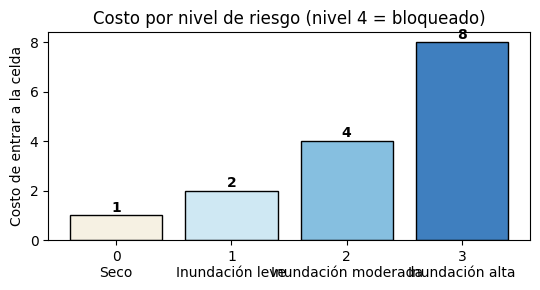

Costo mínimo por paso: 1 → usado en h(n) = costo_min × Manhattan


In [21]:
niveles = list(COSTOS)
fig, ax = plt.subplots(figsize=(5.5, 3))
barras = ax.bar([f"{n}\n{NOMBRES_NIVEL[n].split(' (')[0]}" for n in niveles], [COSTOS[n] for n in niveles],
                color=["#f6f1e3", "#cfe8f3", "#86bfe0", "#3f7fbf"], edgecolor="black")
for b, n in zip(barras, niveles):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.15, str(COSTOS[n]), ha="center", fontweight="bold")
ax.set_ylabel("Costo de entrar a la celda")
ax.set_title("Costo por nivel de riesgo (nivel 4 = bloqueado)")
plt.tight_layout(); plt.show()
print("Costo mínimo por paso:", min(COSTOS.values()), "→ usado en h(n) = costo_min × Manhattan")

## 4. Algoritmos: BFS, UCS y A\*

Los tres comparten la misma interfaz y el mismo criterio de conteo (**E11**):

* **expandidos**: nodos extraídos de la frontera y procesados (la prueba de meta se hace aquí, al extraer).
* **generados**: nodos insertados en la frontera.

| Algoritmo | Frontera | ¿Usa costos? | Garantía |
|---|---|---|---|
| **BFS** | Cola FIFO | No (solo transitabilidad) | Mínimo de **movimientos** |
| **UCS** | Cola de prioridad por `g(n)` | Sí | Mínimo **costo** |
| **A\*** | Cola de prioridad por `g(n)+h(n)` | Sí + heurística | Mínimo **costo** si `h` es admisible (y consistente) |

La prueba de meta se hace **al extraer** (no al generar) en UCS y A\*: es la forma que garantiza optimalidad en cualquier modelo de costos (ver el mutante M6 en la sección 9).

In [22]:
@dataclass
class Resultado:
    algoritmo: str
    encontrada: bool
    ruta: Optional[list]       # lista de celdas (fila, col) de inicio a refugio, o None
    costo: Optional[float]     # costo total, o None si no hay ruta
    movimientos: Optional[int]
    expandidos: int
    generados: int


def costo_ruta(t, ruta):
    """Costo de una ruta (suma de costos de entrada, sin contar el inicio)."""
    return sum(t.costo_entrada(p) for p in ruta[1:])


def _reconstruir(padre, meta):
    ruta = [meta]
    while padre[ruta[-1]] is not None:
        ruta.append(padre[ruta[-1]])
    return ruta[::-1]


def _resultado(nombre, t, padre, meta, exp, gen):
    if meta is None:                       # E7: sin ruta ≠ ruta vacía
        return Resultado(nombre, False, None, None, None, exp, gen)
    ruta = _reconstruir(padre, meta)
    return Resultado(nombre, True, ruta, costo_ruta(t, ruta), len(ruta) - 1, exp, gen)


def bfs(t):
    """Búsqueda en anchura: ignora costos; minimiza movimientos."""
    padre = {t.inicio: None}
    frontera = deque([t.inicio])
    exp, gen = 0, 1
    while frontera:
        n = frontera.popleft(); exp += 1
        if n == t.refugio:
            return _resultado("BFS", t, padre, n, exp, gen)
        for v in t.vecinos(n):
            if v not in padre:
                padre[v] = n; frontera.append(v); gen += 1
    return _resultado("BFS", t, padre, None, exp, gen)


def ucs(t):
    """Costo uniforme (Dijkstra con meta): expande por menor g(n)."""
    cnt = itertools.count()                      # desempate determinista
    g = {t.inicio: 0}; padre = {t.inicio: None}
    pq = [(0, next(cnt), t.inicio)]
    exp, gen = 0, 1
    while pq:
        gn, _, n = heapq.heappop(pq)
        if gn > g[n]:                            # entrada obsoleta
            continue
        exp += 1
        if n == t.refugio:                       # meta al EXTRAER
            return _resultado("UCS", t, padre, n, exp, gen)
        for v in t.vecinos(n):
            ng = gn + t.costo_entrada(v)
            if ng < g.get(v, float("inf")):
                g[v] = ng; padre[v] = n
                heapq.heappush(pq, (ng, next(cnt), v)); gen += 1
    return _resultado("UCS", t, padre, None, exp, gen)


def astar(t, h=None):
    """A*: expande por menor f(n)=g(n)+h(n). Por defecto h = costo_min × Manhattan."""
    h = h or t.heuristica
    cnt = itertools.count()
    g = {t.inicio: 0}; padre = {t.inicio: None}
    pq = [(h(t.inicio), next(cnt), 0, t.inicio)]
    exp, gen = 0, 1
    while pq:
        f, _, gn, n = heapq.heappop(pq)
        if gn > g[n]:                            # entrada obsoleta
            continue
        exp += 1
        if n == t.refugio:
            return _resultado("A*", t, padre, n, exp, gen)
        for v in t.vecinos(n):
            ng = gn + t.costo_entrada(v)
            if ng < g.get(v, float("inf")):
                g[v] = ng; padre[v] = n
                heapq.heappush(pq, (ng + h(v), next(cnt), ng, v)); gen += 1
    return _resultado("A*", t, padre, None, exp, gen)


ALGORITMOS = {"BFS": bfs, "UCS": ucs, "A*": astar}

def ejecutar_todos(t):
    return {nombre: f(t) for nombre, f in ALGORITMOS.items()}

## 5. Validación automática de rutas y verificador independiente

Hay **tres capas** de verificación, deliberadamente separadas (E6, E9):

1. `validar_ruta`: ¿la ruta **respeta las restricciones**? (empieza en el inicio, termina en el refugio, pasos adyacentes, sin obstáculos, sin agua profunda, sin salirse del mapa, sin ciclos).
2. `optimo_independiente`: un **oráculo** que calcula el costo mínimo real con otro método (Bellman-Ford por relajación repetida, **sin** colas de prioridad ni heurísticas) y `alcanzable` (relleno por inundación). No comparten código con los algoritmos.
3. `auditar`: combina lo anterior: validez **y** optimalidad (costo mínimo para UCS/A\*, mínimo de movimientos para BFS), y que "sin ruta" solo se informe cuando de verdad no existe.

In [23]:
def costo_real(t, ruta):
    """Costo de una ruta calculado SIN lanzar excepciones (usa la tabla real del terreno)."""
    return sum(t.costos[int(t.grid[p])] for p in ruta[1:])


def validar_ruta(t, ruta):
    """Devuelve la lista de problemas de una ruta (lista vacía = ruta válida)."""
    if not ruta:
        return ["ruta vacía"]
    ruta = [tuple(p) for p in ruta]
    problemas = []
    if ruta[0] != t.inicio:
        problemas.append(f"no empieza en el inicio {t.inicio} (empieza en {ruta[0]})")
    if ruta[-1] != t.refugio:
        problemas.append(f"no termina en el refugio {t.refugio} (termina en {ruta[-1]})")
    for p in ruta:
        if not t.en_rango(p):
            problemas.append(f"celda fuera del mapa {p}")
        elif t.grid[p] == OBSTACULO:
            problemas.append(f"atraviesa un obstáculo en {p}")
        elif t.grid[p] >= NIVEL_BLOQUEADO:
            problemas.append(f"atraviesa agua profunda (bloqueada) en {p}")
    for a, b in zip(ruta, ruta[1:]):
        if abs(a[0] - b[0]) + abs(a[1] - b[1]) != 1:
            problemas.append(f"salto no adyacente {a} → {b}")
    if len(set(ruta)) != len(ruta):
        problemas.append("la ruta repite celdas (ciclo)")
    return problemas


def optimo_independiente(t, unitario=False):
    """Costo mínimo inicio→refugio por relajación repetida (Bellman-Ford sobre la cuadrícula).
    unitario=True ignora el riesgo (cada paso cuesta 1) → número mínimo de movimientos."""
    INF = float("inf")
    c = (lambda p: 1) if unitario else (lambda p: t.costos[int(t.grid[p])])
    d = {}
    for r in range(t.filas):
        for k in range(t.cols):
            if t.transitable((r, k)):
                d[(r, k)] = INF
    d[t.inicio] = 0
    cambio = True
    while cambio:
        cambio = False
        for p in d:
            for dr, dc in MOVS:
                q = (p[0] + dr, p[1] + dc)
                if q in d and d[q] + c(p) < d[p]:
                    d[p] = d[q] + c(p); cambio = True
    return d[t.refugio]


def alcanzable(t):
    """¿Existe alguna ruta válida inicio→refugio? (relleno por inundación con pila)."""
    visto, pila = {t.inicio}, [t.inicio]
    while pila:
        n = pila.pop()
        if n == t.refugio:
            return True
        for dr, dc in MOVS:
            q = (n[0] + dr, n[1] + dc)
            if t.transitable(q) and q not in visto:
                visto.add(q); pila.append(q)
    return False


def auditar(t, res, criterio="costo"):
    """Lista de problemas del resultado `res` en el terreno REAL `t`. criterio: 'costo' o 'movimientos'."""
    problemas = []
    existe = alcanzable(t)
    if not res.encontrada:
        if existe:
            problemas.append("informa 'sin ruta' pero el refugio SÍ es alcanzable")
        return problemas
    if not existe:
        problemas.append("devuelve una ruta pero el refugio NO es alcanzable")
    pv = validar_ruta(t, res.ruta)
    problemas += pv
    if pv:                                   # con celdas inválidas no tiene sentido recalcular costos
        return problemas
    real = costo_real(t, res.ruta)
    if res.costo != real:
        problemas.append(f"costo reportado {res.costo} ≠ costo recalculado {real}")
    if res.movimientos != len(res.ruta) - 1:
        problemas.append(f"movimientos reportados {res.movimientos} ≠ {len(res.ruta) - 1}")
    if criterio == "costo" and real > optimo_independiente(t):
        problemas.append(f"no es de costo mínimo: {real} > óptimo {optimo_independiente(t)}")
    if criterio == "movimientos" and len(res.ruta) - 1 > optimo_independiente(t, unitario=True):
        problemas.append("no es de mínimos movimientos")
    return problemas


CRITERIO = {"BFS": "movimientos", "UCS": "costo", "A*": "costo"}


RESULTADOS_PRUEBAS = []     # (prueba, estado, detalle) → se resume en la sección 11
METRICAS = {}               # números que se citan luego en las conclusiones

def registrar(nombre, condicion, detalle):
    RESULTADOS_PRUEBAS.append((nombre, "PASS" if condicion else "FAIL", detalle))
    print(("✔ PASS  " if condicion else "✘ FAIL  ") + nombre + " — " + detalle)
    assert condicion, f"Falló: {nombre} — {detalle}"

## 6. Visualización

Colores: tonos de azul = nivel de inundación (más oscuro = más profundo/riesgoso), gris = obstáculo, azul marino con **X** = agua profunda bloqueada. El número dentro de la celda es el nivel de riesgo. **S** = inicio (verde), **R** = refugio (rojo).

In [24]:
COLORES = ["#f6f1e3", "#cfe8f3", "#86bfe0", "#3f7fbf", "#14315c", "#6b6b6b"]   # niveles 0-4 y obstáculo
CMAP = ListedColormap(COLORES)
NORM = BoundaryNorm(np.arange(-0.5, 6.5, 1), CMAP.N)
ESTILO_ALGO = {"BFS": ("#d62728", "-"), "UCS": ("#2ca02c", "--"), "A*": ("#ff7f0e", ":")}


def dibujar_terreno(t, rutas=None, ax=None, titulo="", leyenda=True):
    """rutas: dict {nombre: ruta}. Dibuja el terreno y, opcionalmente, las rutas encima."""
    if ax is None:
        _, ax = plt.subplots(figsize=(0.62 * t.cols + 1.5, 0.62 * t.filas + 1.2))
    img = np.where(t.grid == OBSTACULO, 5, t.grid)
    ax.imshow(img, cmap=CMAP, norm=NORM, origin="upper")
    for r in range(t.filas):
        for c in range(t.cols):
            v = t.grid[r, c]
            if v in (1, 2, 3):
                ax.text(c, r, str(v), ha="center", va="center", fontsize=9, color="white" if v == 3 else "black")
            elif v == NIVEL_BLOQUEADO:
                ax.text(c, r, "X", ha="center", va="center", fontsize=9, color="white", fontweight="bold")
    ax.set_xticks(np.arange(-.5, t.cols, 1), minor=True); ax.set_yticks(np.arange(-.5, t.filas, 1), minor=True)
    ax.grid(which="minor", color="white", linewidth=0.8); ax.tick_params(which="both", length=0)
    ax.set_xticks(range(t.cols)); ax.set_yticks(range(t.filas))
    ax.tick_params(labelsize=7)
    if rutas:
        n = len(rutas)
        for i, (nombre, ruta) in enumerate(rutas.items()):
            if not ruta:
                continue
            off = (i - (n - 1) / 2) * 0.13
            col, ls = ESTILO_ALGO.get(nombre, ("black", "-"))
            ax.plot([p[1] + off for p in ruta], [p[0] + off for p in ruta], ls, color=col, lw=2.2, label=nombre, zorder=3)
    ax.text(t.inicio[1], t.inicio[0], "S", ha="center", va="center", fontweight="bold",
            bbox=dict(boxstyle="circle", fc="#2ca02c", ec="black"), zorder=5)
    ax.text(t.refugio[1], t.refugio[0], "R", ha="center", va="center", fontweight="bold", color="white",
            bbox=dict(boxstyle="circle", fc="#d62728", ec="black"), zorder=5)
    ax.set_title(titulo, fontsize=10)
    if leyenda:
        handles = [Patch(fc=COLORES[i], ec="black", label=f"{i}: {NOMBRES_NIVEL[i].split(' (')[0]}") for i in range(5)]
        handles.append(Patch(fc=COLORES[5], ec="black", label="Obstáculo"))
        if rutas:
            handles += [Line2D([0], [0], color=ESTILO_ALGO.get(k, ("k", "-"))[0], ls=ESTILO_ALGO.get(k, ("k", "-"))[1], lw=2, label=k)
                        for k in rutas if rutas[k]]
        ax.legend(handles=handles, loc="center left", bbox_to_anchor=(1.01, 0.5), fontsize=7, frameon=False)
    return ax


def riesgo_acumulado(t, ruta):
    return int(sum(t.grid[p] for p in ruta[1:]))


def comparar(t, resultados):
    """Tabla comparativa de resultados REALES (costo, movimientos, nodos, riesgo y validez)."""
    filas = []
    for nombre, r in resultados.items():
        if r.encontrada:
            niveles = [int(t.grid[p]) for p in r.ruta[1:]]
            filas.append({"Algoritmo": nombre, "¿Ruta?": "sí", "Costo total": r.costo, "Movimientos": r.movimientos,
                          "Expandidos": r.expandidos, "Generados": r.generados,
                          "Riesgo acum. (suma de niveles)": sum(niveles), "Nivel máx.": max(niveles),
                          "Celdas nivel ≥2": sum(n >= 2 for n in niveles),
                          "Válida": "sí" if not validar_ruta(t, r.ruta) else "NO"})
        else:
            filas.append({"Algoritmo": nombre, "¿Ruta?": "NO EXISTE", "Costo total": None, "Movimientos": None,
                          "Expandidos": r.expandidos, "Generados": r.generados,
                          "Riesgo acum. (suma de niveles)": None, "Nivel máx.": None, "Celdas nivel ≥2": None, "Válida": "n/a"})
    return pd.DataFrame(filas).set_index("Algoritmo")


def dibujar_comparacion(t, resultados, titulo=""):
    """Un panel por algoritmo, con su ruta y sus métricas."""
    n = len(resultados)
    fig, axs = plt.subplots(1, n, figsize=(4.3 * n, 4.3 * t.filas / t.cols + 0.9))
    axs = np.atleast_1d(axs)
    for ax, (nombre, r) in zip(axs, resultados.items()):
        sub = f"{nombre}: costo {r.costo}, {r.movimientos} mov., {r.expandidos} exp." if r.encontrada else f"{nombre}: NO EXISTE RUTA ({r.expandidos} exp.)"
        dibujar_terreno(t, {nombre: r.ruta} if r.encontrada else None, ax=ax, titulo=sub, leyenda=False)
    fig.suptitle(titulo, fontweight="bold")
    plt.tight_layout(rect=[0, 0, 1, 0.94]); plt.show()


def grafica_metricas(df, titulo=""):
    fig, axs = plt.subplots(1, 3, figsize=(11, 3))
    for ax, col in zip(axs, ["Costo total", "Movimientos", "Expandidos"]):
        colores = [ESTILO_ALGO[a][0] for a in df.index]
        ax.bar(df.index, df[col].astype(float), color=colores, edgecolor="black")
        for i, v in enumerate(df[col]):
            ax.text(i, float(v), str(v), ha="center", va="bottom", fontsize=9)
        ax.set_title(col)
    fig.suptitle(titulo, fontweight="bold")
    plt.tight_layout(); plt.show()

## 7. Escenario base

Un **río** (columnas 5-6) separa el inicio `S` (izquierda) del refugio `R` (derecha). Hay varias formas de cruzarlo:

* **Directo** por la fila 5: pasa 2 celdas de nivel 3 (costo 8 c/u).
* **Vado** en la fila 3: celdas de nivel 1 y 2 (mucho más seguro, pero hay que subir 2 filas).
* **Puente seco** en la fila 0: sin riesgo, pero obliga a subir 5 filas y volver a bajar.
* Las filas 8-9 del río son **agua profunda**: no se pueden cruzar.

El camino más directo (en línea recta) **no** es el mejor: justo lo que la actividad quiere evidenciar.

Escenario base: 10x12 | obstáculos: 6, secas: 94, nivel 1: 3, nivel 2: 1, nivel 3: 12, agua profunda: 4
Inicio: (5, 0) | Refugio: (5, 11) | Costos: {0: 1, 1: 2, 2: 4, 3: 8}


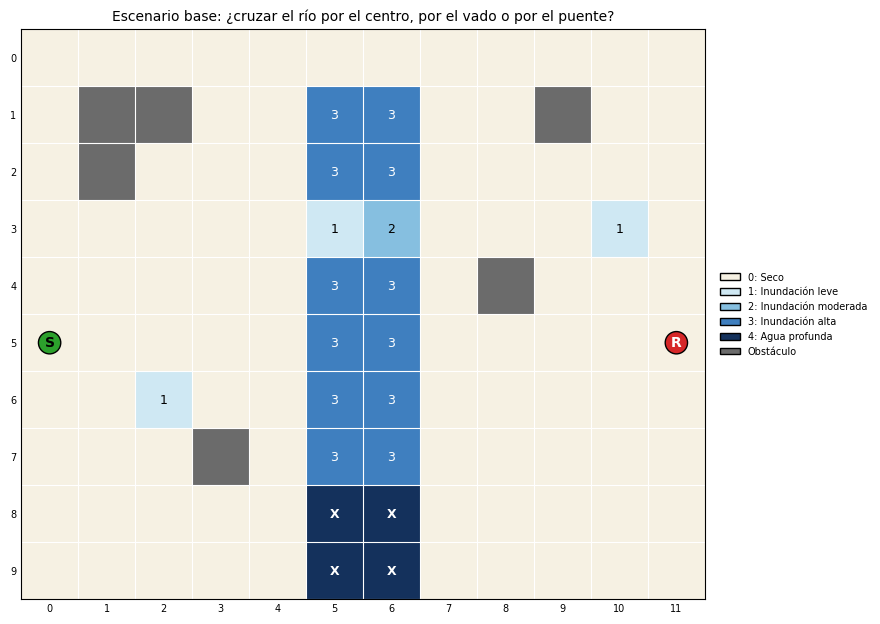

In [25]:
MAPA_BASE = """
. . . . . . . . . . . .
. # # . . 3 3 . . # . .
. # . . . 3 3 . . . . .
. . . . . 1 2 . . . 1 .
. . . . . 3 3 . # . . .
S . . . . 3 3 . . . . R
. . 1 . . 3 3 . . . . .
. . . # . 3 3 . . . . .
. . . . . X X . . . . .
. . . . . X X . . . . .
"""

def escenario_base():
    return Terreno.desde_texto(MAPA_BASE)

base = escenario_base()
print("Escenario base:", base.describir())
print("Inicio:", base.inicio, "| Refugio:", base.refugio, "| Costos:", base.costos)
dibujar_terreno(base, titulo="Escenario base: ¿cruzar el río por el centro, por el vado o por el puente?")
plt.show()

## 8. Las cinco pruebas obligatorias

Cada prueba imprime resultados reales, dibuja las rutas, audita cada ruta con el verificador independiente y registra `PASS/FAIL` con un `assert` (si algo falla, el notebook se detiene).

### Prueba 1 — Ruta disponible
Se ejecutan los tres algoritmos en el escenario base. Deben encontrar ruta, respetar las restricciones y, en UCS/A\*, alcanzar el **costo mínimo** que calcula el verificador independiente.

,¿Ruta?,Costo total,Movimientos,Expandidos,Generados,Riesgo acum. (suma de niveles),Nivel máx.,Celdas nivel ≥2,Válida
Algoritmo,,,,,,,,,
BFS,sí,25,11,82,91,6,3,2,sí
UCS,sí,19,15,91,100,3,2,1,sí
A*,sí,19,15,56,79,3,2,1,sí


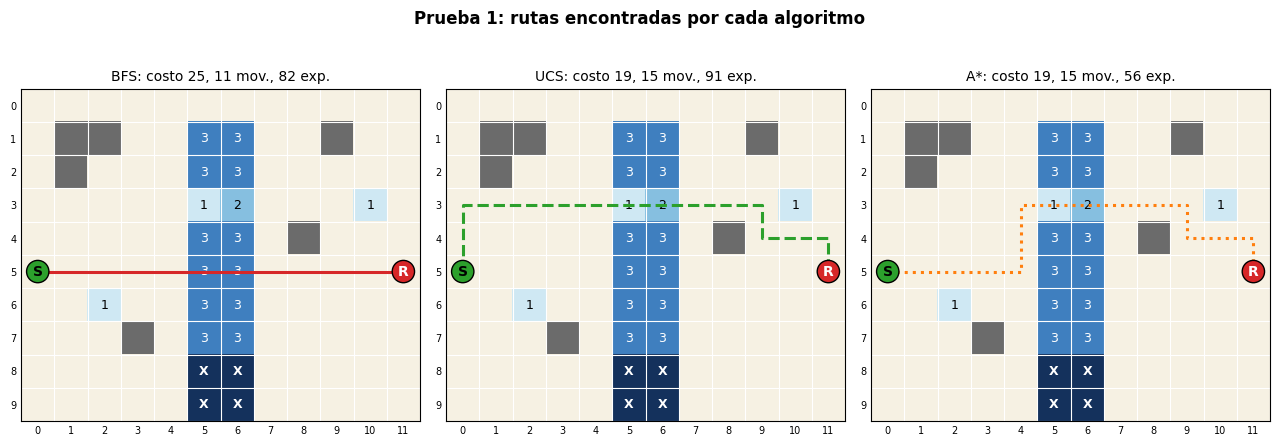

Costo mínimo según el verificador independiente: 19 | Mínimo de movimientos: 11
✔ PASS  P1 BFS ruta válida y óptima en su criterio — sin problemas
✔ PASS  P1 UCS ruta válida y óptima en su criterio — sin problemas
✔ PASS  P1 A* ruta válida y óptima en su criterio — sin problemas
✔ PASS  P1 UCS y A* coinciden con el costo mínimo independiente — UCS=19, A*=19, óptimo=19


In [26]:
t1 = escenario_base()
res1 = ejecutar_todos(t1)
df1 = comparar(t1, res1)
display(df1)
dibujar_comparacion(t1, res1, "Prueba 1: rutas encontradas por cada algoritmo")

opt1 = optimo_independiente(t1)
print("Costo mínimo según el verificador independiente:", opt1,
      "| Mínimo de movimientos:", optimo_independiente(t1, unitario=True))

for nombre, r in res1.items():
    p = auditar(t1, r, CRITERIO[nombre])
    registrar(f"P1 {nombre} ruta válida y óptima en su criterio", r.encontrada and not p, "sin problemas" if not p else "; ".join(p))
registrar("P1 UCS y A* coinciden con el costo mínimo independiente",
          res1["UCS"].costo == res1["A*"].costo == opt1, f"UCS={res1['UCS'].costo}, A*={res1['A*'].costo}, óptimo={opt1}")
METRICAS["p1"] = df1

### Prueba 2 — Bloqueo de una zona
Se bloquea con agua profunda (nivel 4) una celda clave de la ruta óptima (el vado). Las rutas deben **cambiar**, **no** pisar la celda bloqueada y el costo mínimo **no puede bajar** (agregar una restricción nunca hace el problema más fácil).

Celda que se bloquea (agua profunda): (3, 5) | nivel original: 1


,¿Ruta?,Costo total,Movimientos,Expandidos,Generados,Riesgo acum. (suma de niveles),Nivel máx.,Celdas nivel ≥2,Válida
Algoritmo,,,,,,,,,
BFS,sí,25,11,81,90,6,3,2,sí
UCS,sí,21,21,93,99,0,0,0,sí
A*,sí,21,21,78,95,0,0,0,sí


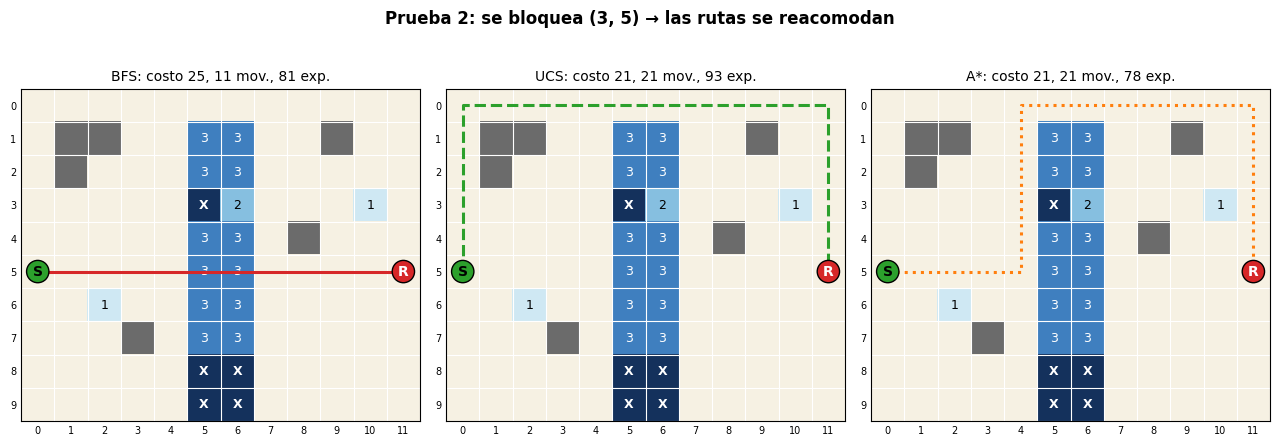

✔ PASS  P2 BFS válida tras el bloqueo — sin problemas
✔ PASS  P2 BFS no pisa la celda bloqueada — celda (3, 5) ausente de la ruta
✔ PASS  P2 UCS válida tras el bloqueo — sin problemas
✔ PASS  P2 UCS no pisa la celda bloqueada — celda (3, 5) ausente de la ruta
✔ PASS  P2 A* válida tras el bloqueo — sin problemas
✔ PASS  P2 A* no pisa la celda bloqueada — celda (3, 5) ausente de la ruta
✔ PASS  P2 la ruta óptima cambió y el costo no bajó — costo 19 → 21
✔ PASS  P2 UCS y A* siguen igualando el óptimo independiente — óptimo=21


In [27]:
t2 = escenario_base()
ruta_vado = res1["UCS"].ruta
celda_bloqueada = next(p for p in ruta_vado if p[1] == 5)     # celda de la ruta óptima en la columna 5 del río
print("Celda que se bloquea (agua profunda):", celda_bloqueada, "| nivel original:", int(t2.grid[celda_bloqueada]))
t2.grid[celda_bloqueada] = NIVEL_BLOQUEADO

res2 = ejecutar_todos(t2)
df2 = comparar(t2, res2)
display(df2)
dibujar_comparacion(t2, res2, f"Prueba 2: se bloquea {celda_bloqueada} → las rutas se reacomodan")

opt2 = optimo_independiente(t2)
for nombre, r in res2.items():
    p = auditar(t2, r, CRITERIO[nombre])
    registrar(f"P2 {nombre} válida tras el bloqueo", not p, "sin problemas" if not p else "; ".join(p))
    registrar(f"P2 {nombre} no pisa la celda bloqueada", celda_bloqueada not in r.ruta, f"celda {celda_bloqueada} ausente de la ruta")
registrar("P2 la ruta óptima cambió y el costo no bajó",
          res2["UCS"].ruta != res1["UCS"].ruta and res2["UCS"].costo >= res1["UCS"].costo,
          f"costo {res1['UCS'].costo} → {res2['UCS'].costo}")
registrar("P2 UCS y A* siguen igualando el óptimo independiente", res2["UCS"].costo == res2["A*"].costo == opt2, f"óptimo={opt2}")
METRICAS["p2_antes"], METRICAS["p2_despues"] = res1["UCS"].costo, res2["UCS"].costo

### Prueba 3 — Refugio inaccesible
Dos formas distintas de aislar el refugio: **(a)** rodearlo de agua profunda, **(b)** cortar todo el río con agua profunda. En ambos casos los tres algoritmos deben informar `NO EXISTE RUTA` (sin devolver rutas vacías, parciales ni costos), y el verificador independiente debe coincidir.

**(a) refugio rodeado de agua profunda**

,¿Ruta?,Costo total,Movimientos,Expandidos,Generados,Riesgo acum. (suma de niveles),Nivel máx.,Celdas nivel ≥2,Válida
Algoritmo,,,,,,,,,
BFS,NO EXISTE,None,None,106,106,None,None,None,n/a
UCS,NO EXISTE,None,None,106,106,None,None,None,n/a
A*,NO EXISTE,None,None,106,116,None,None,None,n/a


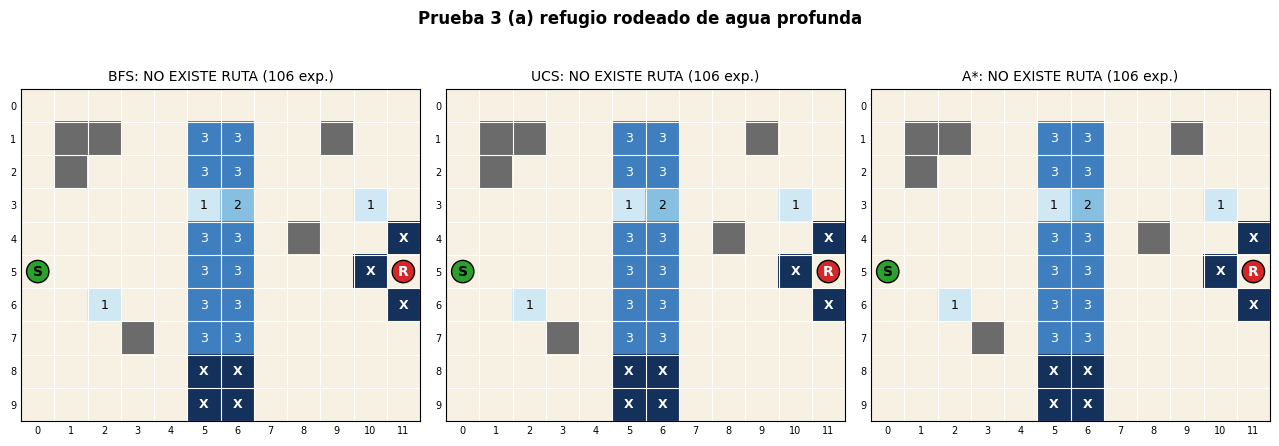

✔ PASS  P3(a) verificador de alcanzabilidad dice 'no alcanzable' — alcanzable()=False
✔ PASS  P3(a) óptimo independiente = ∞ — costo mínimo = inf
✔ PASS  P3(a) BFS informa correctamente que NO hay ruta — encontrada=False, ruta=None, costo=None, expandidos=106
✔ PASS  P3(a) UCS informa correctamente que NO hay ruta — encontrada=False, ruta=None, costo=None, expandidos=106
✔ PASS  P3(a) A* informa correctamente que NO hay ruta — encontrada=False, ruta=None, costo=None, expandidos=106


**(b) río completamente cortado**

,¿Ruta?,Costo total,Movimientos,Expandidos,Generados,Riesgo acum. (suma de niveles),Nivel máx.,Celdas nivel ≥2,Válida
Algoritmo,,,,,,,,,
BFS,NO EXISTE,None,None,46,46,None,None,None,n/a
UCS,NO EXISTE,None,None,46,46,None,None,None,n/a
A*,NO EXISTE,None,None,46,49,None,None,None,n/a


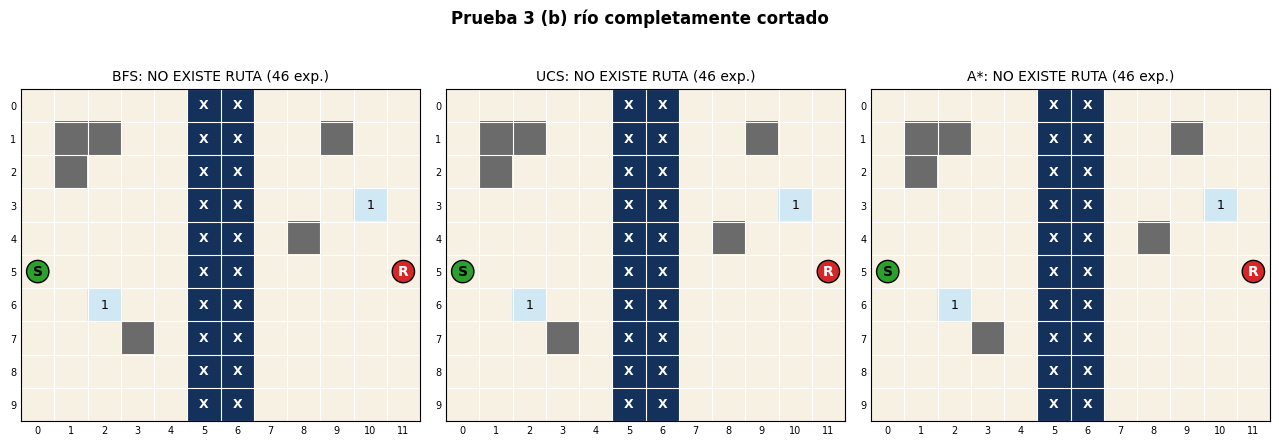

✔ PASS  P3(b) verificador de alcanzabilidad dice 'no alcanzable' — alcanzable()=False
✔ PASS  P3(b) óptimo independiente = ∞ — costo mínimo = inf
✔ PASS  P3(b) BFS informa correctamente que NO hay ruta — encontrada=False, ruta=None, costo=None, expandidos=46
✔ PASS  P3(b) UCS informa correctamente que NO hay ruta — encontrada=False, ruta=None, costo=None, expandidos=46
✔ PASS  P3(b) A* informa correctamente que NO hay ruta — encontrada=False, ruta=None, costo=None, expandidos=46

Contraste (modelo INCORRECTO, agua profunda = costo 1000): ruta encontrada=True, costo=2009
→ Un modelo así 'cruzaría' agua profunda; la restricción del enunciado exige bloquearla.


In [28]:
# (a) refugio rodeado de agua profunda
t3a = escenario_base()
for p in [(4, 11), (6, 11), (5, 10)]:
    t3a.grid[p] = NIVEL_BLOQUEADO
# (b) río completamente cortado: columnas 5-6 en todas las filas son agua profunda
t3b = escenario_base()
t3b.grid[:, 5:7] = NIVEL_BLOQUEADO

for etiqueta, t3 in (("(a) refugio rodeado de agua profunda", t3a), ("(b) río completamente cortado", t3b)):
    res3 = ejecutar_todos(t3)
    display(Markdown(f"**{etiqueta}**"))
    display(comparar(t3, res3))
    dibujar_comparacion(t3, res3, f"Prueba 3 {etiqueta}")
    registrar(f"P3{etiqueta[:3]} verificador de alcanzabilidad dice 'no alcanzable'", not alcanzable(t3), "alcanzable()=False")
    registrar(f"P3{etiqueta[:3]} óptimo independiente = ∞", optimo_independiente(t3) == float("inf"), "costo mínimo = inf")
    for nombre, r in res3.items():
        ok = (not r.encontrada) and r.ruta is None and r.costo is None and r.movimientos is None
        registrar(f"P3{etiqueta[:3]} {nombre} informa correctamente que NO hay ruta", ok and not auditar(t3, r, CRITERIO[nombre]),
                  f"encontrada={r.encontrada}, ruta={r.ruta}, costo={r.costo}, expandidos={r.expandidos}")

# Contraste (ver E3): si el agua profunda fuera un costo alto en vez de un bloqueo, el refugio parecería alcanzable
fake = t3b.copia(); fake.costos[NIVEL_BLOQUEADO] = 1000
fake.transitable = lambda p: fake.en_rango(p) and fake.grid[p] != OBSTACULO
r_fake = ucs(fake)
print(f"\nContraste (modelo INCORRECTO, agua profunda = costo 1000): ruta encontrada={r_fake.encontrada}, costo={r_fake.costo}")
print("→ Un modelo así 'cruzaría' agua profunda; la restricción del enunciado exige bloquearla.")

### Prueba 4 — Modificación del riesgo
Se mantiene el mapa y se cambia **solo el nivel de riesgo del río** (todas las celdas de las columnas 5-6, filas 1-7, incluido el vado). Si el riesgo influye de verdad en la decisión, UCS/A\* deben **cambiar de ruta** al variar el riesgo, mientras que BFS (que ignora el riesgo) siempre elige el mismo camino recto.

,UCS costo,UCS mov.,A* costo,BFS costo,BFS mov.,Decisión de UCS
Nivel del río,,,,,,
0 (Seco),11,11,11,11,11,cruza el río (celdas de río pisadas: 2)
1 (Inundación leve),13,11,13,13,11,cruza el río (celdas de río pisadas: 2)
2 (Inundación moderada),17,11,17,17,11,cruza el río (celdas de río pisadas: 2)
3 (Inundación alta),21,21,21,25,11,usa el puente seco (fila 0)
4 (Agua profunda),21,21,21,21,21,usa el puente seco (fila 0)


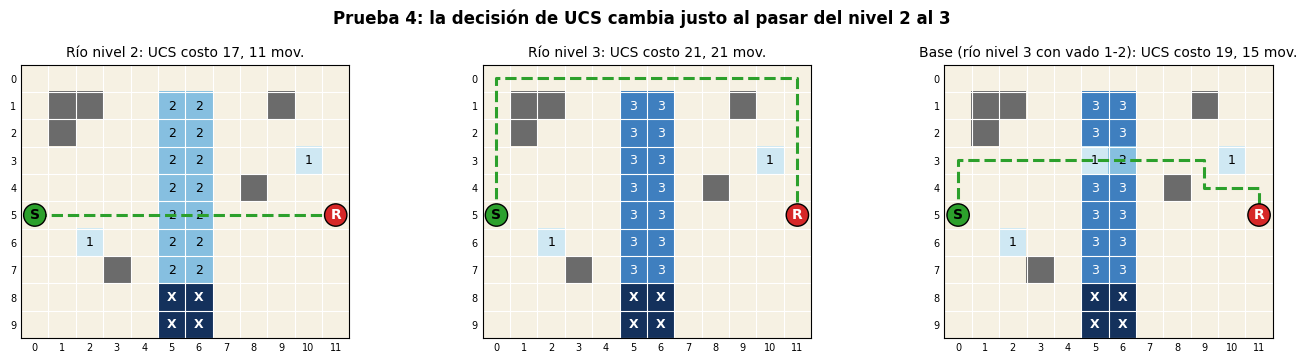

→ Con riesgo del río < 3 UCS cruza el río; con riesgo ≥ 3 prefiere el rodeo por el puente seco.
✔ PASS  P4 el costo óptimo no disminuye al subir el riesgo — costos UCS por nivel 0..4 = [11, 13, 17, 21, 21]
✔ PASS  P4 la decisión cambia con el riesgo — 2 rutas distintas en 5 niveles; la decisión cambia en el nivel 3
✔ PASS  P4 con riesgo mínimo UCS cruza; con agua profunda NO cruza — nivel 0 cruza el río, nivel 4 usa el puente
✔ PASS  P4 BFS ignora el riesgo: misma ruta en niveles 0-3 — BFS no cambia de camino aunque cambie el riesgo


,UCS costo,UCS mov.,Niveles máx. pisados,Celdas de río pisadas
Política de costos,,,,
"Lineal {1,2,3,4}",17,11,3,2
"Base (duplica) {1,2,4,8}",19,15,2,2
"Muy prudente {1,3,9,27}",21,21,0,0


In [29]:
def con_rio_nivel(t, nivel):
    """Copia del terreno con el nivel de riesgo de las celdas del río (cols 5-6, filas 1-7) fijado en `nivel`."""
    x = t.copia()
    x.grid[1:8, 5:7] = nivel
    return x

def en_rio(p):                       # celda del tramo de río con riesgo variable
    return 1 <= p[0] <= 7 and p[1] in (5, 6)

filas = []
rutas_p4 = {}
for nivel in range(0, 5):
    x = con_rio_nivel(base, nivel)
    u, a, b = ucs(x), astar(x), bfs(x)
    cruza = sum(en_rio(p) for p in u.ruta)
    ruta_txt = "cruza el río (celdas de río pisadas: %d)" % cruza if cruza else "usa el puente seco (fila 0)"
    filas.append({"Nivel del río": f"{nivel} ({NOMBRES_NIVEL[nivel].split(' (')[0]})",
                  "UCS costo": u.costo, "UCS mov.": u.movimientos, "A* costo": a.costo, "BFS costo": b.costo, "BFS mov.": b.movimientos,
                  "Decisión de UCS": ruta_txt})
    rutas_p4[nivel] = (x, u)
    for nombre, r in (("UCS", u), ("A*", a), ("BFS", b)):
        p = auditar(x, r, CRITERIO[nombre])
        assert not p, (nivel, nombre, p)
df4 = pd.DataFrame(filas).set_index("Nivel del río")
display(df4)

# Nivel mínimo de riesgo del río a partir del cual UCS deja de cruzarlo
nivel_cambio = next(n for n in range(5) if sum(en_rio(p) for p in rutas_p4[n][1].ruta) == 0)
base_ucs = ucs(base)
paneles = [(rutas_p4[nivel_cambio - 1][0], rutas_p4[nivel_cambio - 1][1], f"Río nivel {nivel_cambio - 1}"),
           (rutas_p4[nivel_cambio][0], rutas_p4[nivel_cambio][1], f"Río nivel {nivel_cambio}"),
           (base, base_ucs, "Base (río nivel 3 con vado 1-2)")]
fig, axs = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, (x, u, nom) in zip(axs, paneles):
    dibujar_terreno(x, {"UCS": u.ruta}, ax=ax, titulo=f"{nom}: UCS costo {u.costo}, {u.movimientos} mov.", leyenda=False)
fig.suptitle(f"Prueba 4: la decisión de UCS cambia justo al pasar del nivel {nivel_cambio - 1} al {nivel_cambio}", fontweight="bold")
plt.tight_layout(); plt.show()
print(f"→ Con riesgo del río < {nivel_cambio} UCS cruza el río; con riesgo ≥ {nivel_cambio} prefiere el rodeo por el puente seco.")

costos_ucs = [rutas_p4[n][1].costo for n in range(5)]
rutas_distintas = {tuple(rutas_p4[n][1].ruta) for n in range(5)}
registrar("P4 el costo óptimo no disminuye al subir el riesgo", all(a <= b for a, b in zip(costos_ucs, costos_ucs[1:])), f"costos UCS por nivel 0..4 = {costos_ucs}")
registrar("P4 la decisión cambia con el riesgo", len(rutas_distintas) >= 2 and 0 < nivel_cambio <= 4,
          f"{len(rutas_distintas)} rutas distintas en 5 niveles; la decisión cambia en el nivel {nivel_cambio}")
registrar("P4 con riesgo mínimo UCS cruza; con agua profunda NO cruza",
          sum(en_rio(p) for p in rutas_p4[0][1].ruta) > 0 and sum(en_rio(p) for p in rutas_p4[4][1].ruta) == 0, "nivel 0 cruza el río, nivel 4 usa el puente")
registrar("P4 BFS ignora el riesgo: misma ruta en niveles 0-3",
          len({tuple(bfs(con_rio_nivel(base, n)).ruta) for n in range(0, 4)}) == 1, "BFS no cambia de camino aunque cambie el riesgo")

# Segundo tipo de cambio: la POLÍTICA de costos (no el mapa)
politicas = {"Lineal {1,2,3,4}": {0: 1, 1: 2, 2: 3, 3: 4},
             "Base (duplica) {1,2,4,8}": {0: 1, 1: 2, 2: 4, 3: 8},
             "Muy prudente {1,3,9,27}": {0: 1, 1: 3, 2: 9, 3: 27}}
filas = []
for nombre, cs in politicas.items():
    x = Terreno(base.grid.copy(), base.inicio, base.refugio, cs)
    u = ucs(x); a = astar(x)
    assert not auditar(x, u) and not auditar(x, a)
    assert u.costo == a.costo == optimo_independiente(x)
    filas.append({"Política de costos": nombre, "UCS costo": u.costo, "UCS mov.": u.movimientos,
                  "Niveles máx. pisados": max(int(x.grid[p]) for p in u.ruta[1:]),
                  "Celdas de río pisadas": sum(en_rio(p) for p in u.ruta)})
df4b = pd.DataFrame(filas).set_index("Política de costos")
display(df4b)
METRICAS["p4"] = df4
METRICAS["nivel_cambio"] = nivel_cambio

### Prueba 5 — Comparación entre la ruta más corta y la más conveniente
**"Más corta"** = menos movimientos (BFS). **"Más conveniente"** = menor costo por riesgo (UCS/A\*). Se miden ambas, con métricas de riesgo reales. Además se incluye un **contraste**: en un terreno uniforme (todo seco) ambas coinciden, lo que confirma que la diferencia viene del riesgo.

,¿Ruta?,Costo total,Movimientos,Expandidos,Generados,Riesgo acum. (suma de niveles),Nivel máx.,Celdas nivel ≥2,Válida
Algoritmo,,,,,,,,,
BFS,sí,25,11,82,91,6,3,2,sí
UCS,sí,19,15,91,100,3,2,1,sí
A*,sí,19,15,56,79,3,2,1,sí


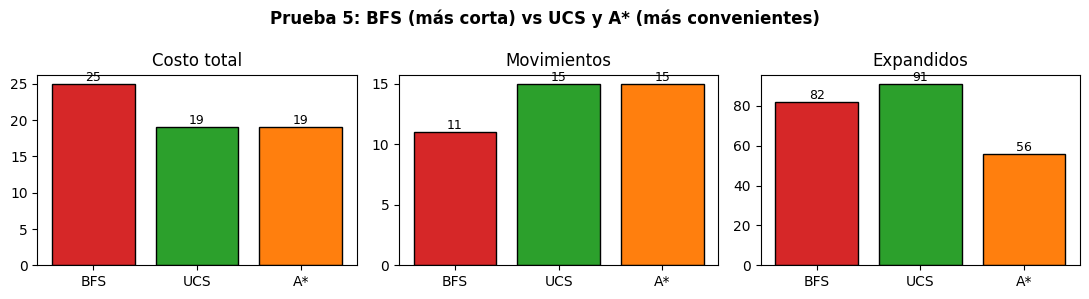

La ruta MÁS CORTA (11 movimientos) cuesta 25; la MÁS CONVENIENTE (15 movimientos) cuesta 19.
→ La ruta corta tiene un costo 31.6% mayor; la conveniente da 4 movimientos más pero pisa 1 celda(s) de riesgo ≥2 menos.
✔ PASS  P5 BFS tiene menos movimientos que UCS — 11 < 15
✔ PASS  P5 UCS tiene menor costo que BFS — 19 < 25
✔ PASS  P5 la ruta más corta es válida pero NO es la conveniente — válida (cumple restricciones) pero con costo > óptimo
✔ PASS  P5 BFS logra el mínimo de movimientos — 11 movimientos
✔ PASS  P5 en terreno uniforme, 'más corta' = 'más conveniente' — costos BFS/UCS/A* = 11/11/11


In [30]:
t5 = escenario_base()
res5 = ejecutar_todos(t5)
df5 = comparar(t5, res5)
display(df5)
grafica_metricas(df5, "Prueba 5: BFS (más corta) vs UCS y A* (más convenientes)")

corta, conveniente = res5["BFS"], res5["UCS"]
sobrecosto = 100 * (corta.costo - conveniente.costo) / conveniente.costo
extra_mov = conveniente.movimientos - corta.movimientos
print(f"La ruta MÁS CORTA ({corta.movimientos} movimientos) cuesta {corta.costo}; la MÁS CONVENIENTE ({conveniente.movimientos} movimientos) cuesta {conveniente.costo}.")
print(f"→ La ruta corta tiene un costo {sobrecosto:.1f}% mayor; la conveniente da {extra_mov} movimientos más pero pisa {df5.loc['BFS','Celdas nivel ≥2'] - df5.loc['UCS','Celdas nivel ≥2']} celda(s) de riesgo ≥2 menos.")

registrar("P5 BFS tiene menos movimientos que UCS", corta.movimientos < conveniente.movimientos, f"{corta.movimientos} < {conveniente.movimientos}")
registrar("P5 UCS tiene menor costo que BFS", conveniente.costo < corta.costo, f"{conveniente.costo} < {corta.costo}")
registrar("P5 la ruta más corta es válida pero NO es la conveniente", not validar_ruta(t5, corta.ruta) and corta.costo > optimo_independiente(t5),
          "válida (cumple restricciones) pero con costo > óptimo")
registrar("P5 BFS logra el mínimo de movimientos", corta.movimientos == optimo_independiente(t5, unitario=True), f"{corta.movimientos} movimientos")

# Contraste: terreno uniforme → la ruta más corta ES la más conveniente
seco = Terreno(np.zeros((10, 12), dtype=int), (5, 0), (5, 11))
rs = ejecutar_todos(seco)
registrar("P5 en terreno uniforme, 'más corta' = 'más conveniente'", rs["BFS"].costo == rs["UCS"].costo == rs["A*"].costo,
          f"costos BFS/UCS/A* = {rs['BFS'].costo}/{rs['UCS'].costo}/{rs['A*'].costo}")
METRICAS["p5_sobrecosto"], METRICAS["p5_extra_mov"], METRICAS["p5"] = sobrecosto, extra_mov, df5

## 9. Prueba adicional: detección de errores de implementación (pruebas de mutación)

Para comprobar que el **sistema de validación realmente detecta bugs**, se introducen errores *a propósito* ("mutantes") y se verifica que `auditar` los atrape en cuadrículas aleatorias (semillas 0-399, tamaños 6-10). Los algoritmos correctos deben tener **0 fallos**.

| Mutante | Error introducido | Debe detectarse como |
|---|---|---|
| **M1** BFS que ignora el bloqueo por inundación | Trata el nivel 4 como transitable | Ruta que atraviesa agua profunda |
| **M2** UCS que ignora el riesgo | Todos los pasos cuestan 1 (equivale a BFS) | Costo reportado ≠ real / no es de costo mínimo |
| **M3** A\* con heurística **inadmisible** | `h = 3 × costo_min × Manhattan` (sobreestima) | Ruta de costo no mínimo |
| **M4** UCS que reporta mal el costo | Devuelve el nº de movimientos como "costo" | Costo reportado ≠ recalculado |
| **M5** UCS que modela el agua profunda como costo 50 | En vez de bloquear (E3) | Ruta por agua profunda / ruta a refugio inaccesible |
| **M6** UCS que marca "visitado" al **insertar** (E-clásico) | Error típico de Dijkstra | *Se mide*: ¿es realmente detectable aquí? |

In [31]:
def generar_aleatorio(semilla):
    """Cuadrícula aleatoria reproducible: tamaño 6-10, inicio arriba-izquierda, refugio abajo-derecha."""
    rnd = random.Random(semilla)
    n = 6 + semilla % 5
    g = np.zeros((n, n), dtype=int)
    for r in range(n):
        for c in range(n):
            x = rnd.random()
            if x < 0.12:   g[r, c] = OBSTACULO
            elif x < 0.22: g[r, c] = NIVEL_BLOQUEADO
            elif x < 0.50: g[r, c] = rnd.choice([1, 2, 3])
    g[0, 0] = 0; g[n - 1, n - 1] = 0
    return Terreno(g, (0, 0), (n - 1, n - 1))


def sin_bloqueo(t, costo_nivel4):
    """Terreno defectuoso: el agua profunda deja de ser un bloqueo."""
    f = t.copia(); f.costos[NIVEL_BLOQUEADO] = costo_nivel4
    f.transitable = lambda p: f.en_rango(p) and f.grid[p] != OBSTACULO
    return f

def con_costos_unitarios(t):
    f = t.copia(); f.costos = {k: 1 for k in f.costos}
    return f


def m1_bfs_ignora_bloqueo(t):  r = bfs(sin_bloqueo(t, 1)); r.algoritmo = "M1"; return r
def m2_ucs_ignora_riesgo(t):   r = ucs(con_costos_unitarios(t)); r.algoritmo = "M2"; return r
def m3_astar_inadmisible(t):   r = astar(t, h=lambda p: 3 * t.heuristica(p)); r.algoritmo = "M3"; return r
def m4_ucs_costo_mal(t):
    r = ucs(t); r.algoritmo = "M4"
    if r.encontrada: r.costo = r.movimientos
    return r
def m5_ucs_agua_costo_alto(t): r = ucs(sin_bloqueo(t, 50)); r.algoritmo = "M5"; return r

def m6_ucs_visitado_al_insertar(t):
    cnt = itertools.count(); g = {t.inicio: 0}; padre = {t.inicio: None}
    pq = [(0, next(cnt), t.inicio)]; visto = {t.inicio}; exp, gen = 0, 1
    while pq:
        gn, _, n = heapq.heappop(pq); exp += 1
        if n == t.refugio:
            r = _resultado("M6", t, padre, n, exp, gen); return r
        for v in t.vecinos(n):
            if v not in visto:
                visto.add(v); g[v] = gn + t.costo_entrada(v); padre[v] = n
                heapq.heappush(pq, (g[v], next(cnt), v)); gen += 1
    return _resultado("M6", t, padre, None, exp, gen)


CANDIDATOS = {   # nombre: (función, criterio de auditoría)
    "BFS (correcto)": (bfs, "movimientos"), "UCS (correcto)": (ucs, "costo"), "A* (correcto)": (astar, "costo"),
    "M1 BFS ignora bloqueo": (m1_bfs_ignora_bloqueo, "movimientos"),
    "M2 UCS ignora riesgo": (m2_ucs_ignora_riesgo, "costo"),
    "M3 A* heurística inadmisible": (m3_astar_inadmisible, "costo"),
    "M4 UCS reporta mal el costo": (m4_ucs_costo_mal, "costo"),
    "M5 UCS agua profunda = costo 50": (m5_ucs_agua_costo_alto, "costo"),
    "M6 UCS visitado al insertar": (m6_ucs_visitado_al_insertar, "costo"),
}

N_ALEATORIOS = 400
detectados = {k: 0 for k in CANDIDATOS}
primer_caso = {}
n_alcanzables = 0
for semilla in range(N_ALEATORIOS):
    t = generar_aleatorio(semilla)
    n_alcanzables += alcanzable(t)
    for nombre, (f, crit) in CANDIDATOS.items():
        r = f(t)
        problemas = auditar(t, r, crit)
        if problemas:
            detectados[nombre] += 1
            primer_caso.setdefault(nombre, (semilla, problemas[0]))

tabla = pd.DataFrame({"Fallos detectados": detectados,
                      f"de {N_ALEATORIOS} cuadrículas": N_ALEATORIOS,
                      "Primer caso (semilla) y problema": {k: (f"{s}: {p}" if k in primer_caso else "—") for k, (s, p) in
                                                           {k: primer_caso.get(k, (None, None)) for k in CANDIDATOS}.items()}})
display(tabla)
print(f"Cuadrículas con refugio alcanzable: {n_alcanzables}/{N_ALEATORIOS} | inalcanzable: {N_ALEATORIOS - n_alcanzables}/{N_ALEATORIOS}")

for k in ("BFS (correcto)", "UCS (correcto)", "A* (correcto)"):
    registrar(f"P6 {k}: 0 fallos en {N_ALEATORIOS} cuadrículas aleatorias", detectados[k] == 0, f"fallos={detectados[k]}")
for k in ("M1 BFS ignora bloqueo", "M2 UCS ignora riesgo", "M3 A* heurística inadmisible", "M4 UCS reporta mal el costo", "M5 UCS agua profunda = costo 50"):
    registrar(f"P6 el validador detecta el error {k.split()[0]}", detectados[k] > 0, f"detectado en {detectados[k]} de {N_ALEATORIOS} cuadrículas")
METRICAS["mutantes"] = detectados
METRICAS["n_alcanzables"] = n_alcanzables

,Fallos detectados,de 400 cuadrículas,Primer caso (semilla) y problema
BFS (correcto),0,400,—
UCS (correcto),0,400,—
A* (correcto),0,400,—
M1 BFS ignora bloqueo,302,400,"1: atraviesa agua profunda (bloqueada) en (3, 6)"
M2 UCS ignora riesgo,318,400,0: costo reportado 10 ≠ costo recalculado 30
M3 A* heurística inadmisible,106,400,4: no es de costo mínimo: 28 > óptimo 22
M4 UCS reporta mal el costo,300,400,0: costo reportado 10 ≠ costo recalculado 18
M5 UCS agua profunda = costo 50,67,400,2: devuelve una ruta pero el refugio NO es alcanzable
M6 UCS visitado al insertar,0,400,—


Cuadrículas con refugio alcanzable: 319/400 | inalcanzable: 81/400
✔ PASS  P6 BFS (correcto): 0 fallos en 400 cuadrículas aleatorias — fallos=0
✔ PASS  P6 UCS (correcto): 0 fallos en 400 cuadrículas aleatorias — fallos=0
✔ PASS  P6 A* (correcto): 0 fallos en 400 cuadrículas aleatorias — fallos=0
✔ PASS  P6 el validador detecta el error M1 — detectado en 302 de 400 cuadrículas
✔ PASS  P6 el validador detecta el error M2 — detectado en 318 de 400 cuadrículas
✔ PASS  P6 el validador detecta el error M3 — detectado en 106 de 400 cuadrículas
✔ PASS  P6 el validador detecta el error M4 — detectado en 300 de 400 cuadrículas
✔ PASS  P6 el validador detecta el error M5 — detectado en 67 de 400 cuadrículas


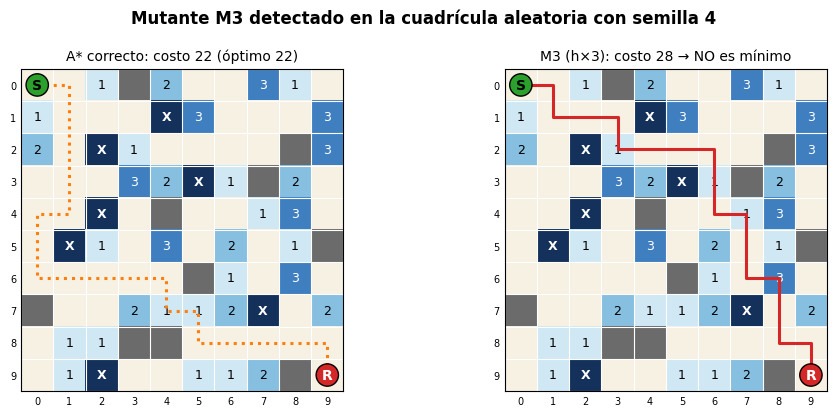

Problemas que reporta el auditor: ['no es de costo mínimo: 28 > óptimo 22']


In [32]:
# Ejemplo visual: A* con heurística inadmisible (M3) vs A* correcto en la primera cuadrícula donde falla
semilla = primer_caso["M3 A* heurística inadmisible"][0]
t = generar_aleatorio(semilla)
bueno, malo = astar(t), m3_astar_inadmisible(t)
fig, axs = plt.subplots(1, 2, figsize=(10, 4.2))
dibujar_terreno(t, {"A*": bueno.ruta}, ax=axs[0], titulo=f"A* correcto: costo {bueno.costo} (óptimo {optimo_independiente(t)})", leyenda=False)
dibujar_terreno(t, {"BFS": malo.ruta}, ax=axs[1], titulo=f"M3 (h×3): costo {malo.costo} → NO es mínimo", leyenda=False)
fig.suptitle(f"Mutante M3 detectado en la cuadrícula aleatoria con semilla {semilla}", fontweight="bold")
plt.tight_layout(); plt.show()
print("Problemas que reporta el auditor:", auditar(t, malo, "costo"))

**Lectura de la tabla.**
* Los tres algoritmos correctos tienen **0 fallos**.
* M1-M5 son **detectados**: la validación no es decorativa.
* **M6** (marcar visitado al insertar) aparece con **0** detecciones: no es un fallo "oculto", es que en este modelo el costo de un paso depende **solo de la celda destino**, así que `g(v) = g(n) + c(v)` y el primer nodo en generar a `v` es el de menor `g`. Es un mutante **equivalente**: no cambia el resultado *en este modelo*. Con costos que dependan de la arista (p. ej. cruzar *de* una zona *a* otra), sí rompería la optimalidad. Por eso nuestra implementación usa la versión general y segura (meta y cierre al **extraer**).

## 10. Verificación final: optimalidad, admisibilidad y pruebas aleatorias

**Admisibilidad (E4, E5).** Se calcula `h*(n)`, el costo real mínimo de cada celda hasta el refugio (relajación independiente) y se comprueba:
* **Admisible:** `h(n) ≤ h*(n)` para toda celda alcanzable.
* **Consistente:** `h(n) ≤ c(n→m) + h(m)` para todo par de celdas vecinas (por eso A\* no necesita reabrir nodos).

In [33]:
def costo_exacto_a_meta(t):
    """h*(n): costo mínimo real de cada celda al refugio (relajación independiente, sin heurística)."""
    INF = float("inf")
    d = {(r, c): INF for r in range(t.filas) for c in range(t.cols) if t.transitable((r, c))}
    d[t.refugio] = 0
    cambio = True
    while cambio:
        cambio = False
        for p in d:
            for dr, dc in MOVS:
                q = (p[0] + dr, p[1] + dc)
                if q in d and d[q] + t.costos[int(t.grid[q])] < d[p]:
                    d[p] = d[q] + t.costos[int(t.grid[q])]; cambio = True
    return d


def verificar_heuristica(t, h=None):
    """Devuelve (violaciones_admisibilidad, violaciones_consistencia, celdas_comprobadas)."""
    h = h or t.heuristica
    hstar = costo_exacto_a_meta(t)
    inadm = [p for p, v in hstar.items() if v < float("inf") and h(p) > v]
    incons = []
    for p in hstar:
        for q in t.vecinos(p):
            if h(p) > t.costo_entrada(q) + h(q):
                incons.append((p, q))
    return len(inadm), len(incons), sum(v < float("inf") for v in hstar.values())

ia, ic, n = verificar_heuristica(base)
registrar("V1 heurística admisible en el escenario base", ia == 0, f"{n} celdas comprobadas, violaciones={ia}")
registrar("V2 heurística consistente en el escenario base", ic == 0, f"violaciones={ic}")

# Contraste: la heurística 3×Manhattan (mutante M3) SÍ es inadmisible
ia3, _, _ = verificar_heuristica(base, h=lambda p: 3 * base.heuristica(p))
registrar("V3 el detector de admisibilidad atrapa una heurística inadmisible (3×)", ia3 > 0, f"{ia3} celdas con h > h*")

# Contraste: Manhattan SIN escalar es admisible aquí solo porque costo_min = 1 (E4)
t_frac = Terreno(base.grid.copy(), base.inicio, base.refugio, {0: 0.5, 1: 1, 2: 2, 3: 4})
manhattan_crudo = lambda p: abs(p[0] - t_frac.refugio[0]) + abs(p[1] - t_frac.refugio[1])
ia_crudo, _, _ = verificar_heuristica(t_frac, h=manhattan_crudo)
ia_esc, ic_esc, _ = verificar_heuristica(t_frac)
registrar("V4 con costo_min=0.5, Manhattan crudo es inadmisible y el escalado sí es admisible", ia_crudo > 0 and ia_esc == 0 and ic_esc == 0,
          f"crudo: {ia_crudo} violaciones | escalado: {ia_esc}")

✔ PASS  V1 heurística admisible en el escenario base — 110 celdas comprobadas, violaciones=0
✔ PASS  V2 heurística consistente en el escenario base — violaciones=0
✔ PASS  V3 el detector de admisibilidad atrapa una heurística inadmisible (3×) — 109 celdas con h > h*
✔ PASS  V4 con costo_min=0.5, Manhattan crudo es inadmisible y el escalado sí es admisible — crudo: 104 violaciones | escalado: 0


In [34]:
# Verificación global en 500 cuadrículas aleatorias (semillas 1000-1499)
filas = []
for semilla in range(1000, 1500):
    t = generar_aleatorio(semilla)
    opt = optimo_independiente(t); opt_mov = optimo_independiente(t, unitario=True)
    r = ejecutar_todos(t)
    ia, ic, _ = verificar_heuristica(t)
    fila = {"semilla": semilla, "alcanzable": alcanzable(t), "óptimo": opt, "adm_viol": ia, "cons_viol": ic}
    for nombre, x in r.items():
        fila[f"{nombre}_problemas"] = len(auditar(t, x, CRITERIO[nombre]))
        fila[f"{nombre}_costo"] = x.costo
        fila[f"{nombre}_exp"] = x.expandidos
    fila["BFS_no_conveniente"] = bool(r["BFS"].encontrada and r["BFS"].costo > opt)
    filas.append(fila)
glob = pd.DataFrame(filas)
al = glob[glob["alcanzable"]]

registrar("V5 ningún algoritmo produce rutas inválidas ni errores de auditoría (500 cuadrículas)",
          int(glob[["BFS_problemas", "UCS_problemas", "A*_problemas"]].sum().sum()) == 0,
          f"{len(glob)} cuadrículas ({len(al)} con ruta posible, {len(glob) - len(al)} sin ruta posible), 0 problemas")
registrar("V6 UCS y A* igualan el costo mínimo independiente en todas las cuadrículas alcanzables",
          bool((al["UCS_costo"] == al["óptimo"]).all() and (al["A*_costo"] == al["óptimo"]).all()), f"{len(al)} cuadrículas comparadas")
registrar("V7 heurística admisible y consistente en las 500 cuadrículas", int(glob["adm_viol"].sum() + glob["cons_viol"].sum()) == 0, "0 violaciones")

resumen = pd.DataFrame({
    "Nodos expandidos (media)": [al["BFS_exp"].mean(), al["UCS_exp"].mean(), al["A*_exp"].mean()],
    "Costo total (media)": [al["BFS_costo"].mean(), al["UCS_costo"].mean(), al["A*_costo"].mean()],
}, index=["BFS", "UCS", "A*"]).round(2)
display(resumen)
print(f"En {int(al['BFS_no_conveniente'].sum())} de {len(al)} cuadrículas con ruta, la ruta más corta (BFS) NO fue la más conveniente.")
print(f"A* expandió menos nodos que UCS en {int((al['A*_exp'] < al['UCS_exp']).sum())} casos, igual en {int((al['A*_exp'] == al['UCS_exp']).sum())} y más en {int((al['A*_exp'] > al['UCS_exp']).sum())}.")
METRICAS["glob_resumen"] = resumen
METRICAS["glob_n"], METRICAS["glob_alc"] = len(glob), len(al)
METRICAS["glob_bfs_no_conv"] = int(al["BFS_no_conveniente"].sum())
METRICAS["glob_astar_menos"] = int((al["A*_exp"] < al["UCS_exp"]).sum())
METRICAS["glob_astar_mas"] = int((al["A*_exp"] > al["UCS_exp"]).sum())

✔ PASS  V5 ningún algoritmo produce rutas inválidas ni errores de auditoría (500 cuadrículas) — 500 cuadrículas (400 con ruta posible, 100 sin ruta posible), 0 problemas
✔ PASS  V6 UCS y A* igualan el costo mínimo independiente en todas las cuadrículas alcanzables — 400 cuadrículas comparadas
✔ PASS  V7 heurística admisible y consistente en las 500 cuadrículas — 0 violaciones


,Nodos expandidos (media),Costo total (media)
BFS,50.48,31.25
UCS,45.78,22.29
A*,33.52,22.29


En 358 de 400 cuadrículas con ruta, la ruta más corta (BFS) NO fue la más conveniente.
A* expandió menos nodos que UCS en 376 casos, igual en 24 y más en 0.


## 11. Tabla resumen de pruebas
Generada automáticamente desde los `registrar(...)` ejecutados (no escrita a mano).

In [35]:
tabla_pruebas = pd.DataFrame(RESULTADOS_PRUEBAS, columns=["Prueba", "Estado", "Detalle"])
pd.set_option("display.max_colwidth", 120); pd.set_option("display.max_rows", 200)
display(tabla_pruebas)
total, ok = len(tabla_pruebas), int((tabla_pruebas["Estado"] == "PASS").sum())
print(f"\nResultado global: {ok}/{total} comprobaciones en PASS")
assert ok == total

,Prueba,Estado,Detalle
0,P1 BFS ruta válida y óptima en su criterio,PASS,sin problemas
1,P1 UCS ruta válida y óptima en su criterio,PASS,sin problemas
2,P1 A* ruta válida y óptima en su criterio,PASS,sin problemas
3,P1 UCS y A* coinciden con el costo mínimo independiente,PASS,"UCS=19, A*=19, óptimo=19"
4,P2 BFS válida tras el bloqueo,PASS,sin problemas
5,P2 BFS no pisa la celda bloqueada,PASS,"celda (3, 5) ausente de la ruta"
6,P2 UCS válida tras el bloqueo,PASS,sin problemas
7,P2 UCS no pisa la celda bloqueada,PASS,"celda (3, 5) ausente de la ruta"
8,P2 A* válida tras el bloqueo,PASS,sin problemas
9,P2 A* no pisa la celda bloqueada,PASS,"celda (3, 5) ausente de la ruta"



Resultado global: 46/46 comprobaciones en PASS


## 12. Decisiones de diseño, errores corregidos, conclusiones y limitaciones

### 12.1 Decisiones de diseño
1. **Riesgo = nivel de inundación**, con costo de entrada `{0:1, 1:2, 2:4, 3:8}`: crece más que linealmente porque el peligro de la corriente lo hace; el mínimo es 1 para poder escalar la heurística.
2. **Agua profunda = restricción dura**, no un costo alto (E3): así "refugio inaccesible" tiene un significado preciso.
3. **Costo de entrar, no de salir; el inicio no cuesta** (E8): una sola convención en todo el código y en el verificador.
4. **Movimientos de 4 direcciones:** hace válida la heurística de Manhattan escalada. Con diagonales habría que cambiar a distancia Chebyshev/octil.
5. **Meta y filtrado al extraer, desempate con contador:** resultados deterministas y óptimos en cualquier modelo de costos.
6. **Verificación en tres capas** (restricciones, oráculo independiente, auditoría) y **pruebas de mutación** para demostrar que el validador atrapa errores reales.

### 12.2 Errores corregidos / prevenidos (resumen de la sección 1)
Costo vs. movimientos (E1, E2); bloqueo vs. costo alto (E3, comprobado en la Prueba 3 y M5); heurística admisible demostrada y no asumida (E4, E5, comprobado en V1-V4 y M3); "sin ruta" bien informado (E7); verificador independiente (E9); conteo de nodos definido (E11). Además, la prueba de mutación mostró que el error clásico de "visitado al insertar" **no** afecta a este modelo de costos (M6): se dejó la versión general por seguridad.

In [36]:
b = METRICAS["p5"]; g = METRICAS["glob_resumen"]
display(Markdown(f"""
### 12.3 Conclusiones (con los números reales de esta ejecución)

1. **Válida ≠ conveniente.** En el escenario base BFS halló la ruta más corta ({int(b.loc['BFS','Movimientos'])} movimientos) y es **válida**, pero cuesta **{int(b.loc['BFS','Costo total'])}** frente a **{int(b.loc['UCS','Costo total'])}** de UCS/A\\*: un sobrecosto de **{METRICAS['p5_sobrecosto']:.1f}%**. La ruta conveniente da **{METRICAS['p5_extra_mov']} movimientos más**, pero pisa {int(b.loc['UCS','Celdas nivel ≥2'])} celda(s) de riesgo ≥2, frente a {int(b.loc['BFS','Celdas nivel ≥2'])} de la ruta corta.
2. **UCS y A\\* son óptimos en costo:** igualaron el óptimo del verificador independiente en el escenario base y en las **{METRICAS['glob_alc']}** cuadrículas aleatorias alcanzables (de {METRICAS['glob_n']}); la heurística resultó admisible y consistente (0 violaciones).
3. **El riesgo gobierna la decisión:** al subir el riesgo del río, UCS dejó de cruzarlo justo en el nivel **{METRICAS['nivel_cambio']}** y pasó a rodear por el puente seco (Prueba 4); BFS no cambió nunca. Al bloquear el vado, el costo óptimo pasó de {METRICAS['p2_antes']} a {METRICAS['p2_despues']} (Prueba 2).
4. **Las restricciones se cumplen:** 0 rutas inválidas en el escenario base, las pruebas y las {METRICAS['glob_n']} cuadrículas aleatorias; el refugio aislado se informa como "sin ruta" en los tres algoritmos.
5. **A\\* vs. UCS (nodos):** en promedio sobre las cuadrículas alcanzables, BFS expandió {g.loc['BFS','Nodos expandidos (media)']}, UCS {g.loc['UCS','Nodos expandidos (media)']} y A\\* {g.loc['A*','Nodos expandidos (media)']} nodos. A\\* expandió menos que UCS en {METRICAS['glob_astar_menos']} cuadrículas y más en {METRICAS['glob_astar_mas']}. El ahorro de A\\* depende de qué tan informativa sea la heurística: la nuestra ignora el riesgo (usa solo el costo mínimo 1), así que subestima en zonas inundadas. Además, **expandir menos nodos no implica mejor ruta**: en el escenario base BFS expandió {int(b.loc['BFS','Expandidos'])} nodos frente a {int(b.loc['UCS','Expandidos'])} de UCS y {int(b.loc['A*','Expandidos'])} de A\\*, pero su ruta fue la más cara.
6. **La validación es efectiva:** de los mutantes M1-M5, todos fueron detectados (conteos en la sección 9).
"""))


### 12.3 Conclusiones (con los números reales de esta ejecución)

1. **Válida ≠ conveniente.** En el escenario base BFS halló la ruta más corta (11 movimientos) y es **válida**, pero cuesta **25** frente a **19** de UCS/A\*: un sobrecosto de **31.6%**. La ruta conveniente da **4 movimientos más**, pero pisa 1 celda(s) de riesgo ≥2, frente a 2 de la ruta corta.
2. **UCS y A\* son óptimos en costo:** igualaron el óptimo del verificador independiente en el escenario base y en las **400** cuadrículas aleatorias alcanzables (de 500); la heurística resultó admisible y consistente (0 violaciones).
3. **El riesgo gobierna la decisión:** al subir el riesgo del río, UCS dejó de cruzarlo justo en el nivel **3** y pasó a rodear por el puente seco (Prueba 4); BFS no cambió nunca. Al bloquear el vado, el costo óptimo pasó de 19 a 21 (Prueba 2).
4. **Las restricciones se cumplen:** 0 rutas inválidas en el escenario base, las pruebas y las 500 cuadrículas aleatorias; el refugio aislado se informa como "sin ruta" en los tres algoritmos.
5. **A\* vs. UCS (nodos):** en promedio sobre las cuadrículas alcanzables, BFS expandió 50.48, UCS 45.78 y A\* 33.52 nodos. A\* expandió menos que UCS en 376 cuadrículas y más en 0. El ahorro de A\* depende de qué tan informativa sea la heurística: la nuestra ignora el riesgo (usa solo el costo mínimo 1), así que subestima en zonas inundadas. Además, **expandir menos nodos no implica mejor ruta**: en el escenario base BFS expandió 82 nodos frente a 91 de UCS y 56 de A\*, pero su ruta fue la más cara.
6. **La validación es efectiva:** de los mutantes M1-M5, todos fueron detectados (conteos en la sección 9).


### 12.4 Limitaciones
* **Terreno estático y conocido:** el agente conoce todo el mapa; no hay crecida del agua en el tiempo ni información parcial.
* **Riesgo por celda, no acumulativo:** no se modela fatiga ni que 3 celdas peligrosas seguidas sean peor que 3 separadas.
* **Costos elegidos, no calibrados:** la política `{1,2,4,8}` es una decisión razonada, no datos reales. La Prueba 4 muestra que otra política puede cambiar la ruta.
* **Movimientos de 4 direcciones y celdas uniformes:** sin diagonales ni distancias reales.
* **Ruta óptima única bajo desempates:** puede haber varias rutas de igual costo; se garantiza el **costo**, no una ruta específica.
* **Aleatorios pequeños (6-10):** suficientes para comparar contra el oráculo, pero no miden rendimiento en mapas grandes. Los conteos de nodos son de nuestra implementación y desempate, no una propiedad general.
* **El oráculo comparte el modelo** (tabla de costos y reglas de transitabilidad): detecta errores de *algoritmo*, no errores en la *definición* del problema.

## 13. Instrucciones de ejecución, estructura del repositorio y commits de Git

### 13.1 Ejecución
```bash
git clone <url-del-repositorio> && cd camino-mas-corto
python -m venv .venv && source .venv/bin/activate      # Windows: .venv\Scripts\activate
pip install numpy pandas matplotlib jupyter
jupyter notebook notebooks/camino_mas_corto.ipynb       # Kernel → Restart & Run All
# o, sin interfaz:
jupyter nbconvert --to notebook --execute notebooks/camino_mas_corto.ipynb --output camino_mas_corto_ejecutado.ipynb
```
Requisitos: Python 3.10+. No hay datos externos ni aleatoriedad sin semilla: dos ejecuciones dan los mismos resultados.

### 13.2 Estructura propuesta del repositorio
El entregable mínimo es el notebook (autocontenido). Esta es la estructura sugerida para el repositorio del equipo:
```
camino-mas-corto/
├── README.md                  # resumen + instrucciones de ejecución (sección 13.1)
├── requirements.txt           # numpy, pandas, matplotlib, jupyter
├── notebooks/
│   └── camino_mas_corto.ipynb # este notebook (código, pruebas, visualizaciones, documentación)
├── docs/
│   └── justificaciones.pdf    # opcional
└── .gitignore                 # .venv/, .ipynb_checkpoints/, __pycache__/
```
Una refactorización posible (opcional) es separar `Terreno`, los algoritmos, la validación y la visualización en `src/` y las pruebas en `tests/` con `pytest`.

### 13.3 Ejemplos de commits descriptivos (convención "tipo: descripción")
```text
feat: representar el terreno como cuadrícula con obstáculos, niveles de inundación y agua profunda bloqueada
feat: implementar BFS, UCS y A* con conteo de nodos expandidos y generados
fix: bloquear el nivel 4 en lugar de asignarle costo alto para que el refugio aislado sea inalcanzable
fix: escalar la heurística de Manhattan por el costo mínimo para mantenerla admisible
feat: agregar validar_ruta y verificador independiente (Bellman-Ford) para auditar optimalidad
test: añadir cinco pruebas obligatorias y comprobación de heurística admisible y consistente
test: añadir pruebas de mutación que detectan heurística inadmisible y bloqueo ignorado
docs: documentar errores de la prueba trampa, decisiones de diseño y limitaciones
docs: declarar uso de herramientas de IA y método de verificación
```

## 14. Declaración de uso de herramientas de IA y verificación

**Herramientas de IA utilizadas:** se utilizó **Claude (Anthropic)** como asistente para estructurar el notebook, redactar la primera versión del código (representación del terreno, BFS, UCS, A\*, validadores, visualizaciones y pruebas) y la documentación en español.

**Cómo se verificó el código (no se confió en la salida del asistente sin comprobarla):**
1. **Ejecución completa:** el notebook se ejecutó de principio a fin (`jupyter nbconvert --execute`), y se conservan las salidas reales en el archivo entregado.
2. **Verificador independiente** (Bellman-Ford sin colas de prioridad, y alcanzabilidad por relleno) para contrastar el costo mínimo de UCS y A\*.
3. **Validador de restricciones:** ninguna ruta atraviesa obstáculos ni agua profunda, empieza/termina donde debe y no tiene saltos.
4. **Comprobación explícita de admisibilidad y consistencia** de la heurística contra `h*(n)` exactos.
5. **Pruebas aleatorias con semilla** (400 + 500 cuadrículas) y **pruebas de mutación** para demostrar que el validador detecta bugs reales.
6. Cada afirmación numérica del documento se imprime desde el código; ninguna cifra se estimó a mano.
